# Quantum model as fourier series

In [41]:
import matplotlib.pyplot as plt
import pennylane as qp
from pennylane import numpy as np

In [6]:
np.random.seed(42)

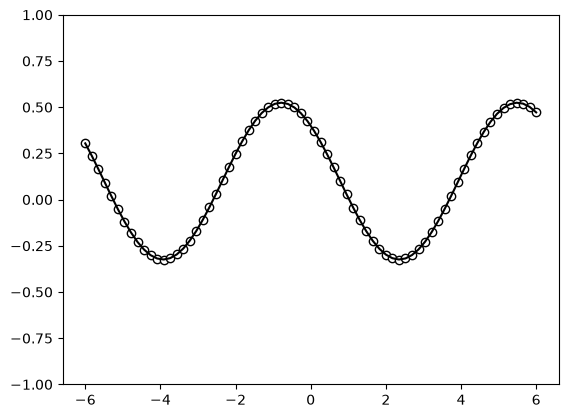

In [34]:
# Define target function g
degree = 1
scaling = 1
c0 = 0.1
cs = [0.15 - 0.15j]

def g(x):
    res = c0
    for n, c in enumerate(cs):
        exponent = np.complex128(-1j * (n + 1) * (scaling * x))
        res += c * np.exp(exponent) + np.conjugate(c) * np.exp(-exponent)
    return np.real(res)

# Plot the target function
xs = np.linspace(-6, 6, 70, requires_grad=False)
target_ys = np.array([g(x) for x in xs], requires_grad=False)

plt.plot(x, target_ys, c="black")
plt.scatter(x, target_ys, facecolor="white", edgecolor="black")
plt.ylim(-1, 1)
plt.show()

0: ──Rot(3.81,5.82,4.09)──RX(6.00)──Rot(5.75,5.34,2.82)─┤  <Z>


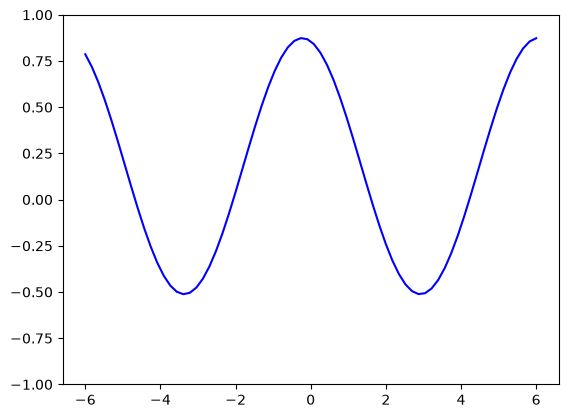

In [32]:
# Define a serial quantum model
dev = qp.device("default.qubit", wires=1)

def S(x):
    qp.RX(scaling * x, wires=0)

def W(theta):
    qp.Rot(theta[0], theta[1], theta[2], wires=0)


@qp.qnode(dev)
def serial_quantum_model(weights, x):
    for theta in weights[:-1]:
        W(theta)
        S(x)
    W(weights[-1])
    return qp.expval(qp.PauliZ(wires=0))

# visualize with random weights
l = 1
weights = (2 * np.pi * np.random.random(size=(l + 1, 3), requires_grad=True))

xs = np.linspace(-6, 6, 70, requires_grad=False)
random_quantum_model_y = [serial_quantum_model(weights, x) for x in xs]
print(qp.draw(serial_quantum_model)(weights, xs[-1]))

plt.plot(x, random_quantum_model_y, c="blue")
plt.ylim(-1, 1)
plt.show()

In [36]:
# Define loss function L
def L(targets, predictions):
    loss = 0
    for t, p in zip(targets, predictions):
        loss += (t - p) ** 2
    loss = loss / len(targets)
    return 0.5 * loss

# Define objective function (cost function)
def cost(weights, xs, ys):
    predictions = [serial_quantum_model(weights, x) for x in xs]
    return square_loss(ys, predictions)

# Training loop
max_steps = 100
opt = qp.AdamOptimizer(0.3)
batch_size = 25
cs = [cost(weights, xs, target_ys)]

for step in range(max_steps):
    batch_index = np.random.randint(0, len(xs), (batch_size,))
    x_batch = x[batch_index]
    y_batch = target_ys[batch_index]
    
    weights, _, _ = opt.step(cost, weights, x_batch, y_batch)
    c = cost(weights, x, target_y)
    cs.append(c)

    if (step + 1) % 10 == 0:
        print("Cost at step {0:3}: {1}".format(step + 1, c))

Cost at step  10: 0.00241243648553063
Cost at step  20: 0.001625834967921663
Cost at step  30: 0.0017697548817472352
Cost at step  40: 0.00011359099082961436
Cost at step  50: 1.3146181399771493e-05
Cost at step  60: 0.0001067489775962762
Cost at step  70: 3.929176436274392e-05
Cost at step  80: 1.542509206125941e-05
Cost at step  90: 1.0563874834192927e-05
Cost at step 100: 8.11394324319333e-06


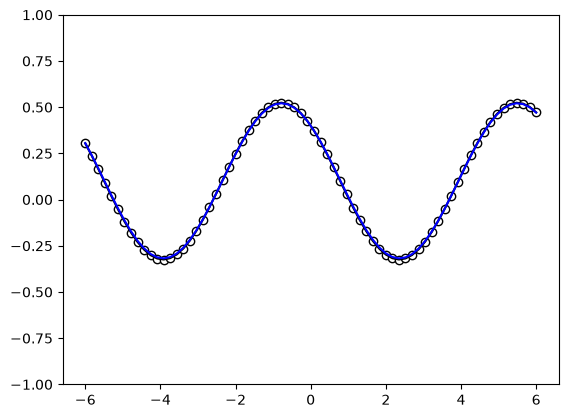

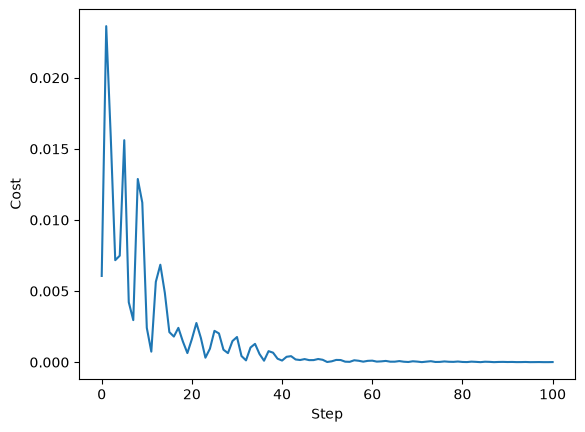

In [40]:
# Inference the quantum circuit
predictions = [serial_quantum_model(weights, x) for x in xs]

plt.plot(xs, target_ys, c="black")
plt.scatter(xs, target_ys, facecolor="white", edgecolor="black")
plt.plot(xs, predictions, c="blue")
plt.ylim(-1, 1)
plt.show()

# Visualise the loss function
plt.plot(range(len(cs)), cs)
plt.ylabel("Cost")
plt.xlabel("Step")
plt.show()